The action-selection model estimates the probability of passing at a frame; the probability of carrying is its complement. These probabilities weight the two risks in the composed hazard. **own derivation**

## Model and inputs

The XGBoost binary logistic model consumes one feature row for the current state. A **feature** is an input summary that describes the available actions or the game state at that frame. The current feature builder has 12 physical summaries and one-hot encoded start-type and previous-action categories (the exact encoded columns are stored with the trained model). **own derivation**

| Feature(s) | Meaning in this implementation |
|---|---|
| `bcos` | Scalar open-space summary supplied by the optional [BCOS extra](../extras/bcos/10_bcos.ipynb). The separate BCOS vignette describes the field and API; the action-selection booster retains this feature from training. The related BCOS concept is described by Bandara et al. [@bandara2025bcos]. |
| `rppcf` | Sum over candidate destinations of transition probability × pass-success probability. This is the model’s transition-weighted expected pass success, using Spearman-style pitch control; the name `rppcf` is project-specific, not a universal term [@spearman2017; @spearman2018beyond]. **own derivation** |
| `ball_drive_prob` | Probability of retaining possession through the modeled drive, i.e. one minus the ball-drive loss probability. **own derivation** |
| `xT_team_pass`, `xT_opp_pass` | Expected Threat summaries over pass destinations. Team xT is weighted by transition probability × pass success; opponent xT by transition probability × pass failure. xT assigns value to locations [@singh2018xt]. Weighting is a **design choice**. |
| `opp_pressure_line_index_pass`, `team_pressure_line_index_pass` | Expected number of opponent or team pressure lines crossed by pass destinations, weighted by transition probability × pass success. **own derivation**; the broad motivation of quantifying pressure is discussed by SkillCorner, whose article does not specify this formula [@skillcorner-pressure]. |
| `team_pressure_line_index_exposure` | Team pressure-line count at pass destinations, weighted by transition probability × pass failure. **own derivation** |
| `xT_team_drive`, `xT_opp_drive`, `opp_pressure_line_index_drive`, `team_pressure_line_index_drive` | Team/opponent xT and pressure-line counts at the carrier’s one-second extrapolated location, x_bc + v_bc × 1 s. The one-second horizon follows the carry-state construction in this code. **own derivation** |
| `start_type_std_*`, `previous_action_std_*` | One-hot encoded action-start category and preceding action from event context. **design choice** |

The trained binary model outputs P(pass | state); P(drive | state)=1−P(pass | state). Elapsed time is deliberately excluded because possession segmentation makes it a proxy for position within the segmented possession. **design choice**

## Usage and visual

The following code uses a deterministic synthetic curve to illustrate how the two action probabilities weight the hazard branches. Its values are computed by the cell and are not predictions from the trained model.

## Component scope

The feature builder and trained booster are in `PRESS/utils/action_selection.py`. This model selects between the two action labels represented in the training data from one checkpoint state; it does not itself estimate branch risk. **model scope**

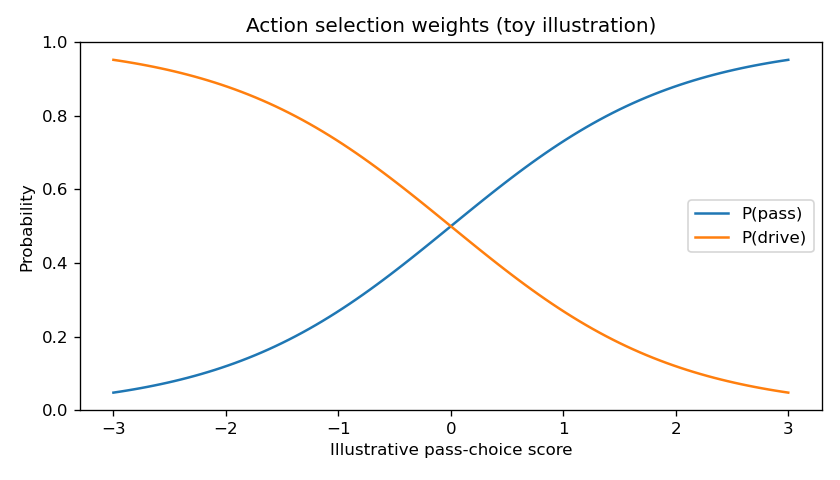

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Illustrative two-class probability curve for increasing pass attractiveness.
# This toy curve explains the mixture weight; it is not a model prediction.
pass_signal=np.linspace(-3,3,101); p_pass=1/(1+np.exp(-pass_signal)); p_drive=1-p_pass
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(pass_signal,p_pass,label="P(pass)"); ax.plot(pass_signal,p_drive,label="P(drive)"); ax.set(xlabel="Illustrative pass-choice score",ylabel="Probability",ylim=(0,1),title="Action selection weights (toy illustration)"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_04_action_selection.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows the tracked state and the scalar pass/carry choice weights. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


{'Pass probability': 0.2826128304004669, 'Ball drive probability': 0.7173871695995331}


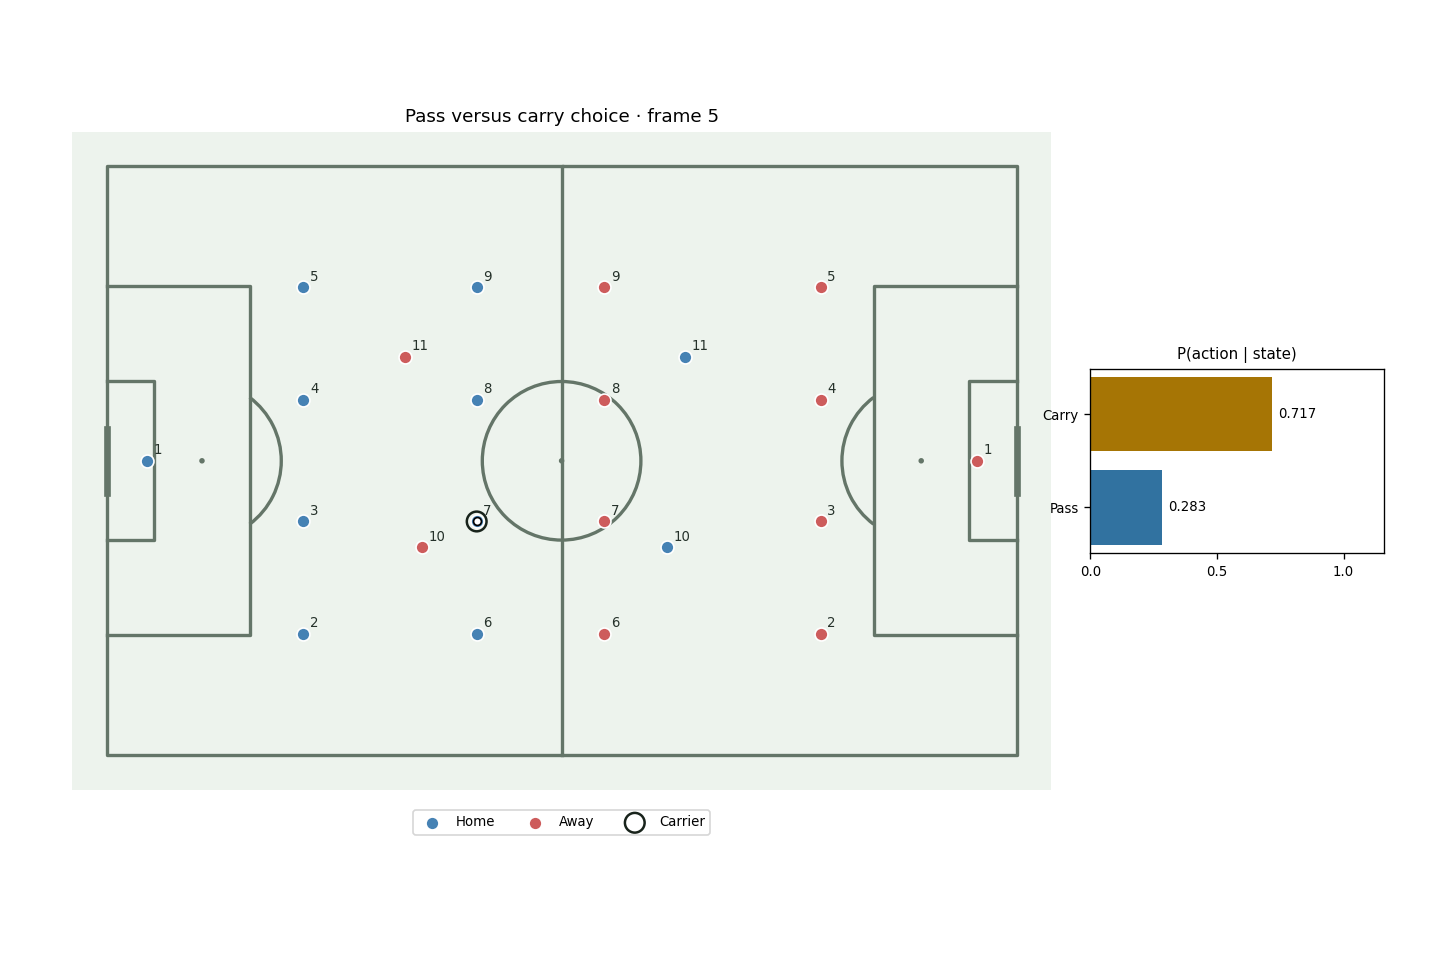

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid)
from PRESS.extras import BCOS
bcos = BCOS(tracking)
bcos_result = bcos.compute_bcos(frame_id, r_max=8, step=4)
bcos_value = float(np.asarray(bcos_result["Ball carrier open space"]).sum())
context = model.get_frame_context(frame_id)
p_pass = model.compute_action_selection_probability(
    frame_id, xT_grid, context["start_type"],
    context["previous_action"], bcos_value,
)
print(model.get_action_selection_result(frame_id))

from PRESS.visualization import plot_action_selection
fig, ax = plot_action_selection(model, frame_id)
out = Path("figures/vignette_04_action_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
